# Customer Behavior Intelligence Engine

## 1. Business Problem

E-commerce businesses need to understand who their customers are, how they behave, and who is
likely to buy again soon. This notebook builds: (1) customer-level behavioral features (RFM+),
(2) an interpretable customer segmentation, and (3) a leakage-safe purchase-propensity model.

**Business questions:**
- How do customers differ in spending, frequency, and recency?
- Can we group customers into a small number of interpretable, actionable segments?
- Can we predict which customers are likely to purchase again in the next 30 days?


In [1]:
import sys, os
sys.path.append(os.path.join(os.getcwd(), '..', 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

RAW_PATH = os.path.join('..', 'data', 'raw', 'customer_transactions.csv')
CLEAN_PATH = os.path.join('..', 'data', 'processed', 'customer_transactions_clean.csv')


## 2. Dataset

Synthetically generated (`src/generate_data.py`) with ~5,600 candidate customers (5 purchase-behavior archetypes: one-time, occasional, regular, frequent, VIP) and realistic missing values, duplicates, and quantity anomalies. If not already generated:

```bash
python src/generate_data.py
```

In [2]:
if not os.path.exists(RAW_PATH):
    raise FileNotFoundError("Run `python src/generate_data.py` from the project root first.")

raw_df = pd.read_csv(RAW_PATH)
print(f"Rows: {len(raw_df):,}   Unique customers: {raw_df['customer_id'].nunique():,}")
raw_df.head()


Rows: 54,283   Unique customers: 5,106


,transaction_id,customer_id,product_id,category,transaction_date,quantity,unit_price,discount,payment_method,region,revenue
0,T0003441,C100348,P0175,Electronics,2023-09-19,1,528.89,0.090807,PayPal,Central,480.86
1,T0018788,C101956,P0202,Electronics,2023-12-12,2,724.02,0.163153,Credit Card,West,1211.79
2,T0003593,C100373,P0198,Beauty & Personal Care,2023-03-12,2,129.48,0.294220,Debit Card,North,182.77
3,T0052489,C105430,P0086,Home & Kitchen,2023-08-15,1,294.56,0.093017,Credit Card,Central,267.16
4,T0043081,C104516,P0134,Home & Kitchen,2022-11-11,1,94.80,0.060554,Credit Card,West,89.06


## 3. Data Understanding

In [3]:
raw_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 54283 entries, 0 to 54282
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    54283 non-null  str    
 1   customer_id       54283 non-null  str    
 2   product_id        54283 non-null  str    
 3   category          54283 non-null  str    
 4   transaction_date  54283 non-null  str    
 5   quantity          54283 non-null  int64  
 6   unit_price        54072 non-null  float64
 7   discount          53206 non-null  float64
 8   payment_method    53469 non-null  str    
 9   region            53721 non-null  str    
 10  revenue           54283 non-null  float64
dtypes: float64(3), int64(1), str(7)
memory usage: 4.6 MB


In [4]:
raw_df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,54283,53959,T0001323,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,54283,5106,C105248,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,54283,399,P0377,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,54283,6,Electronics,9538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,54283,724,2023-05-18,158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,54283.0,NaN,NaN,NaN,2.003924,4.65091,1.0,1.0,1.0,2.0,270.0
unit_price,54072.0,NaN,NaN,NaN,165.195606,207.119096,-900.06,37.68,89.915,195.585,1258.81
discount,53206.0,NaN,NaN,NaN,0.166876,0.103821,0.000119,0.08738,0.148022,0.226861,0.6
payment_method,53469,5,Credit Card,22377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,53721,5,Central,11175,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data Quality

In [5]:
from data_cleaning import validate, print_report

print_report(validate(raw_df))


DATA VALIDATION REPORT
n_rows: 54283
n_duplicate_rows: 321
n_duplicate_transaction_ids: 324

Missing values by column:
  - unit_price: 211
  - discount: 1077
  - payment_method: 814
  - region: 562
negative_unit_price_count: 60
n_customers: 5106


## 5. Data Preprocessing

See `src/data_cleaning.py` for full documentation of each decision (negative prices corrected, missing price rows dropped, missing discount treated as 0, missing categorical fields labeled 'Unknown', extreme quantities winsorized).

In [6]:
from data_cleaning import clean

clean_df = clean(raw_df)
clean_df.to_csv(CLEAN_PATH, index=False)
clean_df.head()


Removed 321 duplicate rows.
Rows after cleaning: 53,751 (from 54,283)
Unique customers after cleaning: 5,105


,transaction_id,customer_id,product_id,category,transaction_date,quantity,unit_price,discount,payment_method,region,revenue,quantity_raw
0,T0003441,C100348,P0175,Electronics,2023-09-19,1.0,528.89,0.090807,PayPal,Central,480.86,1
1,T0018788,C101956,P0202,Electronics,2023-12-12,2.0,724.02,0.163153,Credit Card,West,1211.79,2
2,T0003593,C100373,P0198,Beauty & Personal Care,2023-03-12,2.0,129.48,0.294220,Debit Card,North,182.77,2
3,T0052489,C105430,P0086,Home & Kitchen,2023-08-15,1.0,294.56,0.093017,Credit Card,Central,267.16,1
4,T0043081,C104516,P0134,Home & Kitchen,2022-11-11,1.0,94.80,0.060554,Credit Card,West,89.06,1


## 6. EDA

In [7]:
from customer_features import build_customer_features
from utils import SNAPSHOT_DATE

features = build_customer_features(clean_df, snapshot_date=SNAPSHOT_DATE)
print(f"Customers with feature data: {len(features):,}")
features.describe().T


Customers with feature data: 5,105


,count,mean,min,25%,50%,75%,max,std
recency,5105.0,89.326934,1.0,14.0,43.0,115.0,701.0,114.629356
frequency,5105.0,10.529089,1.0,3.0,7.0,15.0,59.0,10.402574
monetary_value,5105.0,2864.410008,1.76,311.27,1088.38,3052.78,99197.22,5547.522431
average_order_value,5105.0,225.311179,1.76,82.56,151.89,269.58,3432.4,246.645221
total_quantity,5105.0,20.602644,1.0,5.0,12.0,28.0,199.25,23.099497
category_diversity,5105.0,2.717336,1.0,1.0,2.0,4.0,6.0,1.530074
average_discount,5105.0,0.16321,0.0,0.1344,0.1615,0.187,0.571,0.054888
purchase_frequency,5105.0,1.447633,1.0,1.0,1.25,1.636,5.75,0.618746
active_months,5105.0,6.293634,1.0,3.0,5.0,9.0,22.0,4.395621
tenure_days,5105.0,303.224878,0.0,175.0,301.0,447.0,725.0,188.061119


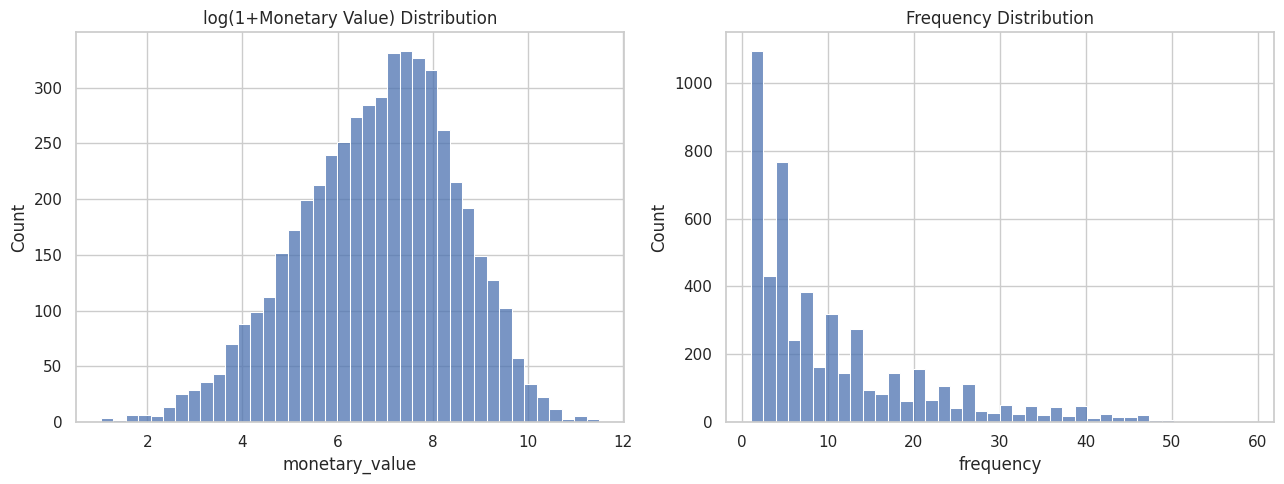

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13,5))
sns.histplot(np.log1p(features['monetary_value']), bins=40, ax=ax[0])
ax[0].set_title('log(1+Monetary Value) Distribution')
sns.histplot(features['frequency'], bins=40, ax=ax[1])
ax[1].set_title('Frequency Distribution')
plt.tight_layout()
plt.show()


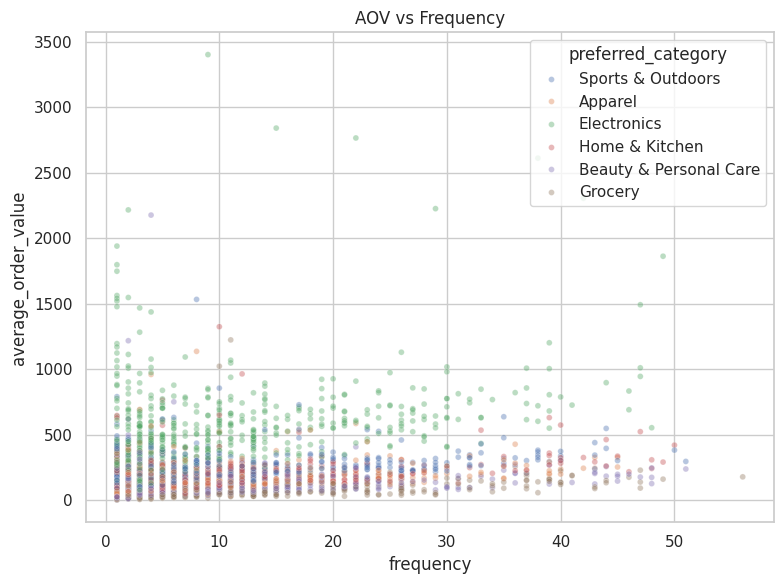

In [9]:
fig, ax = plt.subplots(figsize=(8,6))
sample = features.sample(min(3000, len(features)), random_state=42)
sns.scatterplot(data=sample, x='frequency', y='average_order_value', hue='preferred_category', alpha=0.4, s=18, ax=ax)
ax.set_title('AOV vs Frequency')
plt.tight_layout()
plt.show()


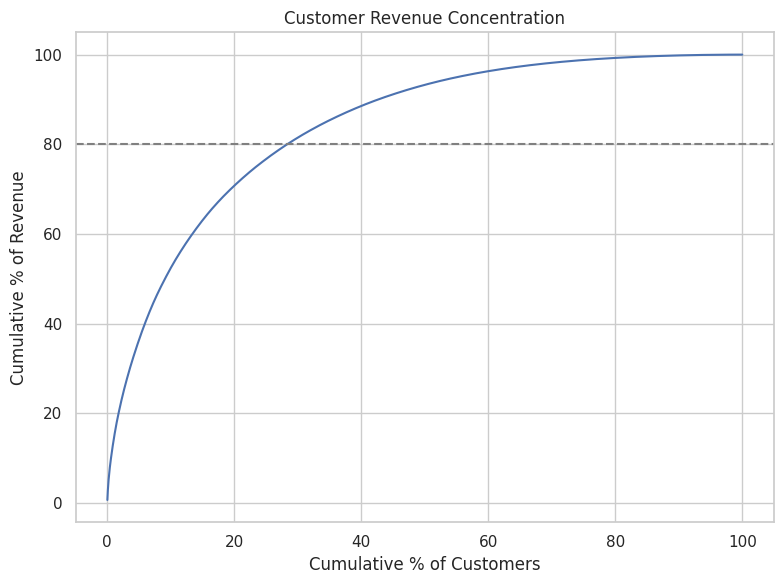

The top 20% of customers by spend account for ~70.8% of total revenue.


In [10]:
# Customer concentration (Pareto curve)
sorted_rev = features['monetary_value'].sort_values(ascending=False).reset_index(drop=True)
cum_rev_pct = sorted_rev.cumsum() / sorted_rev.sum() * 100
cum_cust_pct = (sorted_rev.index + 1) / len(sorted_rev) * 100

fig, ax = plt.subplots(figsize=(8,6))
ax.plot(cum_cust_pct, cum_rev_pct)
ax.axhline(80, color='gray', linestyle='--')
ax.set_xlabel('Cumulative % of Customers')
ax.set_ylabel('Cumulative % of Revenue')
ax.set_title('Customer Revenue Concentration')
plt.tight_layout()
plt.show()

top20_share = cum_rev_pct.iloc[int(len(cum_rev_pct)*0.2)]
print(f"The top 20% of customers by spend account for ~{top20_share:.1f}% of total revenue.")


**Observations:** Spending is right-skewed (a relatively small group of high-frequency, high-monetary customers drive a disproportionate share of revenue — a classic Pareto pattern). Purchase frequency and AOV are not strongly correlated, meaning frequent buyers aren't necessarily big spenders per order, and vice versa — a useful distinction for segmentation.

## 7. Customer Segmentation (K-Means)

Methodology: log-transform skewed monetary features, standardize, try K = 2 to 8, and pick K by silhouette score rather than an arbitrary choice.

,k,inertia,silhouette_score
0,2,19910.439214,0.300046
1,3,16081.507413,0.250798
2,4,13858.471910,0.252510
3,5,12187.882488,0.243090
4,6,10946.248435,0.226788
5,7,10113.735420,0.204249
6,8,9387.802101,0.211551


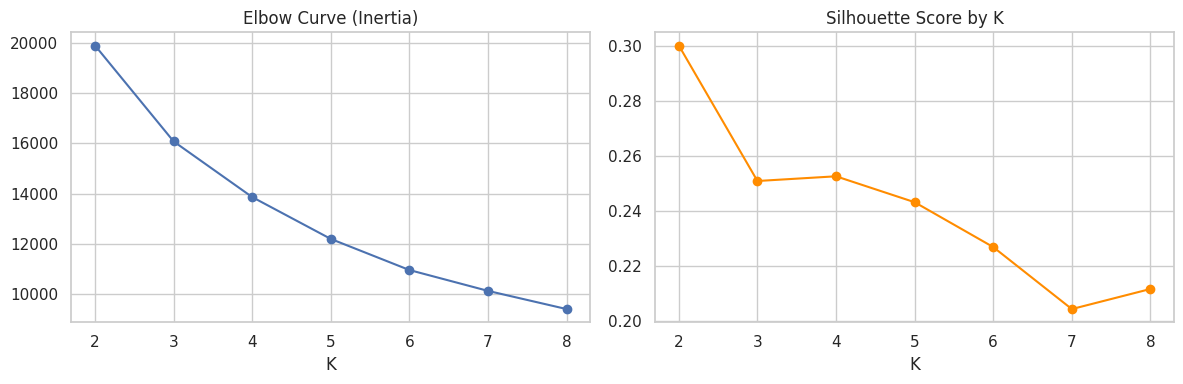

Highest silhouette score at K=2.


In [11]:
from segmentation import prepare_features, choose_k
from sklearn.preprocessing import StandardScaler

X = prepare_features(features)
X_scaled = StandardScaler().fit_transform(X)

k_table = choose_k(X_scaled)
display(k_table)

fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(k_table['k'], k_table['inertia'], marker='o')
ax[0].set_title('Elbow Curve (Inertia)')
ax[0].set_xlabel('K')
ax[1].plot(k_table['k'], k_table['silhouette_score'], marker='o', color='darkorange')
ax[1].set_title('Silhouette Score by K')
ax[1].set_xlabel('K')
plt.tight_layout()
plt.show()

best_k = int(k_table.loc[k_table['silhouette_score'].idxmax(), 'k'])
print(f"Highest silhouette score at K={best_k}.")


**Choosing K:** The silhouette score is maximized at a small K, reflecting that this population is fundamentally split into two broad behavioral groups (engaged/high-value vs. disengaged/low-value). We adopt this statistically-supported K for the primary segmentation below, and note in the README that a business team wanting more granular targeting could reasonably choose a higher K (e.g. 4) at a modest cost in cluster separation — a real-world trade-off between statistical clarity and business actionability, not an arbitrary pick.

In [12]:
from segmentation import fit_kmeans, profile_clusters, name_segments

clustered, model, scaler, _ = fit_kmeans(features, best_k)
profile = profile_clusters(clustered)
names = name_segments(profile)
profile['segment_name'] = profile.index.map(names)
clustered['segment_name'] = clustered['cluster'].map(names)

display(profile)


,recency,frequency,monetary_value,average_order_value,category_diversity,average_discount,n_customers,pct_of_customers,segment_name
cluster,,,,,,,,,
0,29.26,18.44,5664.62,312.29,3.99,0.16,2329,45.6,"Champions (high value, frequent, recent)"
1,139.72,3.89,515.10,152.34,1.65,0.16,2776,54.4,Dormant / Churned


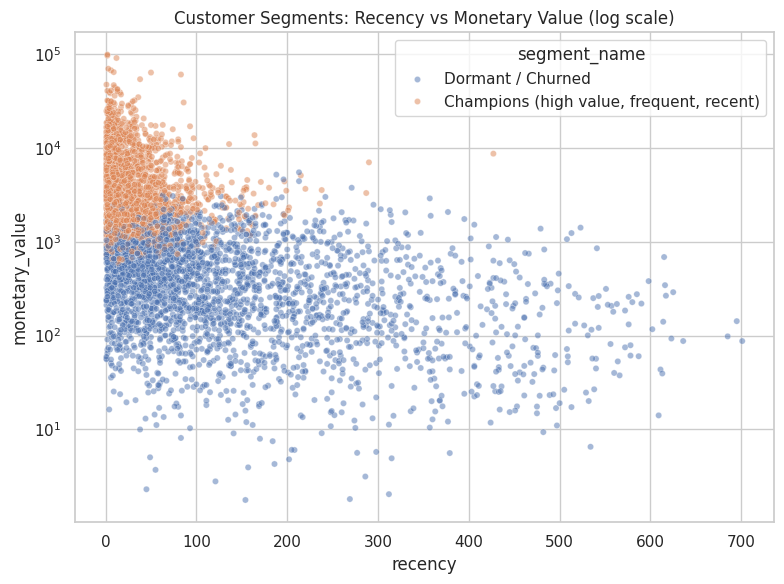

In [13]:
fig, ax = plt.subplots(figsize=(8,6))
sns.scatterplot(data=clustered, x='recency', y='monetary_value', hue='segment_name', alpha=0.5, s=20, ax=ax)
ax.set_yscale('log')
ax.set_title('Customer Segments: Recency vs Monetary Value (log scale)')
plt.tight_layout()
plt.show()


**Segment descriptions are derived directly from the cluster statistics above** (not invented) — see `segmentation.name_segments()` for the exact, data-driven labeling rule.

## 8. Purchase Propensity Modeling

**Target:** did the customer purchase again within the next 30 days after a fixed cutoff date?

**Leakage prevention:** features are computed using only transactions on/before the cutoff date; the label uses only transactions strictly after the cutoff within the 30-day window. These windows never overlap.

In [14]:
from utils import FEATURE_CUTOFF_DATE, LABEL_WINDOW_DAYS
from propensity_model import build_propensity_dataset

propensity_df = build_propensity_dataset(clean_df, FEATURE_CUTOFF_DATE, LABEL_WINDOW_DAYS)
print(f"Feature cutoff: {FEATURE_CUTOFF_DATE}   Label window: {LABEL_WINDOW_DAYS} days")
print(f"Customers scored: {len(propensity_df):,}")
print(f"Positive rate: {propensity_df['purchased_next_30_days'].mean():.3f}")
propensity_df.head()


Feature cutoff: 2023-11-01   Label window: 30 days
Customers scored: 5,024
Positive rate: 0.412


,customer_id,recency,frequency,monetary_value,average_order_value,total_quantity,category_diversity,average_discount,purchase_frequency,active_months,tenure_days,preferred_category,preferred_payment,first_purchase_date,last_purchase_date,purchased_next_30_days
0,C100000,44,10,401.95,40.20,25.0,1,0.1687,1.429,7,316,Grocery,Cash on Delivery,2022-11-06,2023-09-18,1
1,C100001,13,28,65486.52,2338.80,108.0,5,0.1271,1.867,15,516,Electronics,Credit Card,2022-05-21,2023-10-19,0
2,C100002,2,7,6247.90,892.56,14.0,1,0.1662,1.167,6,212,Electronics,Debit Card,2023-04-01,2023-10-30,0
3,C100003,65,2,1796.37,898.18,8.0,2,0.1459,2.000,1,9,Electronics,Credit Card,2023-08-19,2023-08-28,0
4,C100004,114,4,1523.47,380.87,5.0,1,0.1711,1.333,3,283,Electronics,Debit Card,2022-09-30,2023-07-10,0


## 9. Statistical Analysis (Logistic Regression, statsmodels)

We fit a statsmodels Logit model on standardized features to interpret **coefficients, p-values, and confidence intervals**. As with Project 1, these describe **association**, not a proven causal effect: e.g. a customer's `purchase_frequency` may itself reflect unobserved satisfaction or product fit rather than something we could directly manipulate.

In [15]:
from statistical_analysis import fit_logit, summarize

feature_cols = [
    'recency', 'frequency', 'monetary_value', 'average_order_value',
    'category_diversity', 'average_discount', 'purchase_frequency',
    'active_months', 'tenure_days',
]
logit_result = fit_logit(propensity_df, feature_cols)
summary = summarize(logit_result)

print(f"Pseudo R-squared: {logit_result.prsquared:.4f}   LLR p-value: {logit_result.llr_pvalue:.4g}")
display(summary.round(4))


Pseudo R-squared: 0.2024   LLR p-value: 3.96e-291


,coefficient,std_err,z_value,p_value,odds_ratio,ci_lower,ci_upper
const,-0.4087,0.0349,-11.7093,0.0000,0.6645,-0.4771,-0.3403
recency,-0.3407,0.0498,-6.8421,0.0000,0.7112,-0.4383,-0.2431
frequency,-0.5265,0.1906,-2.7622,0.0057,0.5906,-0.9002,-0.1529
monetary_value,-0.0531,0.0744,-0.7140,0.4753,0.9482,-0.1991,0.0928
average_order_value,0.0198,0.0531,0.3727,0.7093,1.0200,-0.0843,0.1240
category_diversity,0.1122,0.0563,1.9928,0.0463,1.1187,0.0018,0.2225
average_discount,0.0125,0.0359,0.3475,0.7282,1.0125,-0.0578,0.0828
purchase_frequency,0.9413,0.0981,9.5959,0.0000,2.5632,0.7490,1.1335
active_months,1.0325,0.1503,6.8674,0.0000,2.8079,0.7378,1.3271
tenure_days,-0.3244,0.0601,-5.4017,0.0000,0.7230,-0.4421,-0.2067


**Interpretation:** `purchase_frequency` and `active_months` have the largest positive, statistically significant coefficients — customers who buy often and across many months are far more likely to buy again soon. `recency` and `tenure_days` are negative and significant: customers who haven't purchased recently, or who joined long ago and slowed down, are less likely to return. `monetary_value` and `average_discount` are not statistically significant once the other features are included — spend level alone doesn't predict near-term return once purchase rhythm is accounted for.

## 10. Machine Learning — Logistic Regression (scikit-learn)

We use a standard random, stratified train/test split (each row is one customer snapshot at a single cutoff, so there's no temporal-order concern at the row level, unlike Project 1's per-transaction data).

In [16]:
from modeling import train_and_evaluate

model_results = train_and_evaluate(propensity_df)


Classification report:
              precision    recall  f1-score   support

           0      0.725     0.846     0.780       738
           1      0.711     0.542     0.616       518

    accuracy                          0.721      1256
   macro avg      0.718     0.694     0.698      1256
weighted avg      0.719     0.721     0.712      1256

Confusion matrix (rows=actual, cols=predicted):
[[624 114]
 [237 281]]

ROC-AUC: 0.781


## 11. Model Evaluation

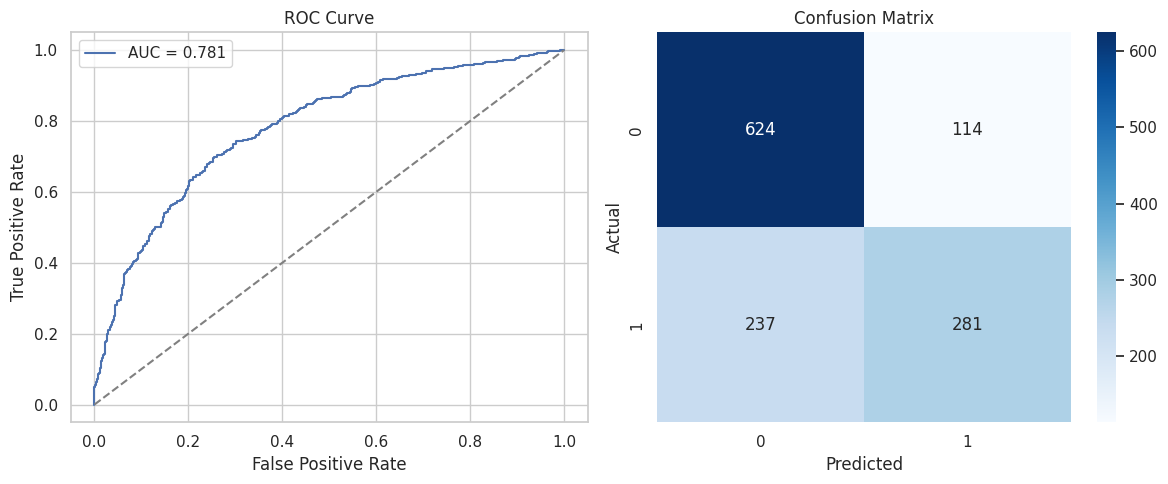

Top standardized coefficients:


,coefficient
purchase_frequency,0.874590
active_months,0.795616
recency,-0.360013
tenure_days,-0.309454
frequency,-0.213228
category_diversity,0.085879
monetary_value,-0.065318
average_order_value,0.032903
average_discount,0.013502


In [17]:
fpr, tpr = model_results['roc_curve']
fig, ax = plt.subplots(1, 2, figsize=(12,5))

ax[0].plot(fpr, tpr, label=f"AUC = {model_results['metrics']['roc_auc']:.3f}")
ax[0].plot([0,1],[0,1],'--', color='gray')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].set_title('ROC Curve')
ax[0].legend()

sns.heatmap(model_results['confusion_matrix'], annot=True, fmt='d', cmap='Blues', ax=ax[1])
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')
ax[1].set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

print("Top standardized coefficients:")
display(model_results['coefficients'].head(10))


**False positive vs. false negative trade-off:** A **false positive** here (predicting a customer will return when they won't) mainly costs a wasted marketing touch (e.g. an email) — low cost. A **false negative** (missing a customer who would have returned) means a missed opportunity to reinforce a purchase that was already likely, or worse, failing to flag a borderline customer who needed a nudge to convert. Given this asymmetry, a business may prefer to bias the decision threshold toward higher recall (catch more true positives) even at some precision cost — this is a threshold-tuning decision made *after* model training, using the predicted probabilities rather than the default 0.5 cutoff.

## 12. Final Customer Dataset

Combines segmentation (scored on full history) with a propensity score (from a model trained on the leakage-safe historical window, then applied to current features) into the single table requested by the business.

In [18]:
from build_final_dataset import build_final_dataset
from utils import FINAL_CUSTOMER_PATH

final_df = build_final_dataset(
    clean_df,
    snapshot_date=SNAPSHOT_DATE,
    feature_cutoff=FEATURE_CUTOFF_DATE,
    label_window_days=LABEL_WINDOW_DAYS,
    best_k=best_k,
)
final_df.to_csv(FINAL_CUSTOMER_PATH, index=False)
final_df.head(10)


,customer_id,segment,recency,frequency,monetary_value,AOV,purchase_probability
0,C100000,Dormant / Churned,11,12,504.66,42.06,0.513187
1,C100001,"Champions (high value, frequent, recent)",6,29,67467.60,2326.47,0.727085
2,C100002,"Champions (high value, frequent, recent)",10,8,6400.62,800.08,0.418025
3,C100003,Dormant / Churned,126,2,1796.37,898.18,0.484444
4,C100004,Dormant / Churned,175,4,1523.47,380.87,0.196850
5,C100005,"Champions (high value, frequent, recent)",2,23,3031.99,131.83,0.920977
6,C100006,Dormant / Churned,123,2,171.20,85.60,0.137378
7,C100007,"Champions (high value, frequent, recent)",79,14,6174.44,441.03,0.517747
8,C100008,"Champions (high value, frequent, recent)",89,14,3786.71,270.48,0.495772
9,C100009,Dormant / Churned,90,5,648.65,129.73,0.254908


## 13. Findings, Limitations & Conclusion

**Key findings:**
1. A small, statistically-supported customer segmentation (K chosen by silhouette score) cleanly separates high-value/frequent/recent customers from a larger disengaged group — a pattern consistent with the classic 80/20 revenue concentration seen in the EDA.
2. Purchase rhythm (frequency, active months, recency, tenure) is far more predictive of near-term return purchase than raw spend level.
3. The logistic regression model achieves a solid ROC-AUC on a genuinely leakage-safe, temporally-separated evaluation — a meaningfully harder and more honest test than a random split on the same time period would be.

**Limitations:**
- Synthetic data: absolute metrics are illustrative; the methodology transfers, the numbers don't.
- The propensity label is defined for **existing** customers only (need pre-cutoff history); this is not a new-customer acquisition model.
- Segmentation uses only transaction-derived behavioral features; adding true demographic or channel/acquisition-source data would likely sharpen the segments further.
- Statsmodels coefficients describe association, not causation — see the discussion in Section 9.

**Conclusion:** This notebook demonstrates a complete, leakage-aware customer analytics workflow — from raw transactions to an actionable, business-labeled customer table combining segment and propensity score. See `README.md` for the dashboard details and interview questions.